<a href="https://colab.research.google.com/github/nikolni23/Presentation_TS/blob/main/Presentation_I.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time Series Analysis 2026, Presentation I

## Participant Information

Write your **student IDs** and **names** into the variables in the next cell (`name1`, `studentId1`, and, if you work in a pair, `name2`, `studentId2`). Replace the placeholder text; keep the quotation marks.

**Example for a group of two students**, Sylvia Petrova (7EB0120130) and Petko Petrov (8EB0120132):

```python
name1 = "Sylvia Petrova"
studentId1 = "7EB0120130"
name2 = "Petko Petrov"
studentId2 = "8EB0120132"
```

**Single-person group:** fill in `name1` and `studentId1` only and leave `name2` and `studentId2` untouched (do not edit them). You will then see a warning about the missing second name, which you can ignore.

- At least one name is required. The notebook will stop with an error if `name1` and `name2` are both missing or still contain the defaults.
- The two time series you analyse are selected **at random from your names**, so the same names always give the same series. Please spell your names consistently (capitalisation and extra spaces are ignored).

In [15]:
name1 = "Nikol Nikolova"
studentId1 = "0EB0100155"

name2 = "Polina Stoyneva"
studentId2 = "5EB0100172"

In [16]:
###########################
## DO NOT EDIT THIS CELL ##
###########################

import hashlib
import pandas as pd
import random
import warnings


DEFAULT_NAME1 = "YOUR NAME HERE, e.g. Petko Petrov"
DEFAULT_ID1 = "e.g. 0EB0493240"


def is_filled(value, *defaults):
    value = value.strip()
    return value != "" and value not in defaults


has_name1 = is_filled(name1, DEFAULT_NAME1)
has_name2 = is_filled(name2)

if not (has_name1 or has_name2):
    raise ValueError("Please write at least one name (name1) in the cell above.")

if not has_name2:
    warnings.warn("The second name (name2) is missing or still has the default value. "
                  "Ignore this warning if you submit alone.")
if not is_filled(studentId1, DEFAULT_ID1):
    warnings.warn("studentId1 is missing or still has the default value.")
if has_name2 and not is_filled(studentId2, "..."):
    warnings.warn("studentId2 is missing or still has the default value.")

BASE_URL = "https://raw.githubusercontent.com/febse/data/main/ts/ts2026"
N_SERIES = 50

# Seed derived from the names (order, case and spaces do not matter).
# hashlib is used because Python's built-in hash() changes between sessions.
names = sorted(" ".join(n.lower().split()) for n, ok in [(name1, has_name1), (name2, has_name2)] if ok)
seed = int(hashlib.sha256("|".join(names).encode("utf-8")).hexdigest(), 16)
rng = random.Random(seed)

file1 = f"batch1_{rng.randint(1, N_SERIES):02d}.csv"
file2 = f"batch2_{rng.randint(1, N_SERIES):02d}.csv"
print("Selected series:", file1, file2)

series1 = pd.read_csv(f"{BASE_URL}/{file1}")
series2 = pd.read_csv(f"{BASE_URL}/{file2}")

Selected series: batch1_02.csv batch2_35.csv


In [17]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# 0. Estimation/test split (90% training, 10% test)
n1 = len(series1)
split_idx1 = int(n1 * 0.90)
train1, test1 = series1.iloc[:split_idx1], series1.iloc[split_idx1:]

n2 = len(series2)
split_idx2 = int(n2 * 0.90)
train2, test2 = series2.iloc[:split_idx2], series2.iloc[split_idx2:]

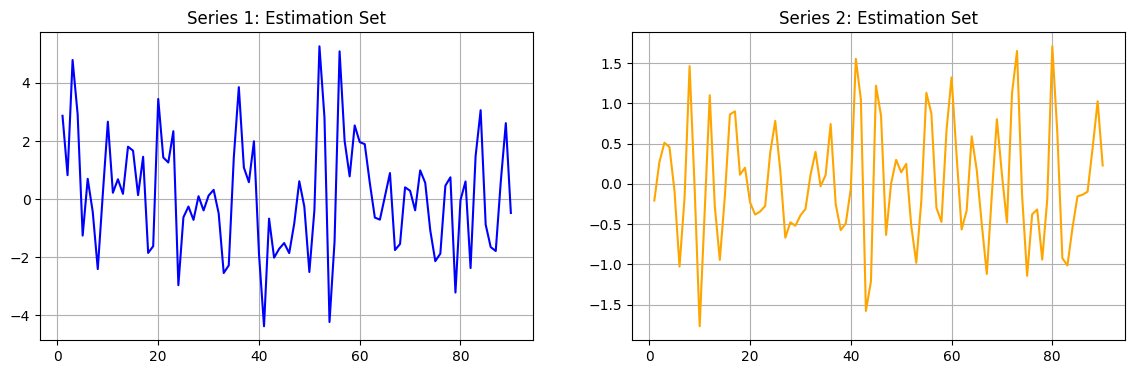

In [18]:
# 1. Time series plot of the training set (Series 1 & Series 2)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(train1['t'], train1['y'], color='blue')
axes[0].set_title('Series 1: Estimation Set')
axes[0].grid(True)

axes[1].plot(train2['t'], train2['y'], color='orange')
axes[1].set_title('Series 2: Estimation Set')
axes[1].grid(True)
plt.show()

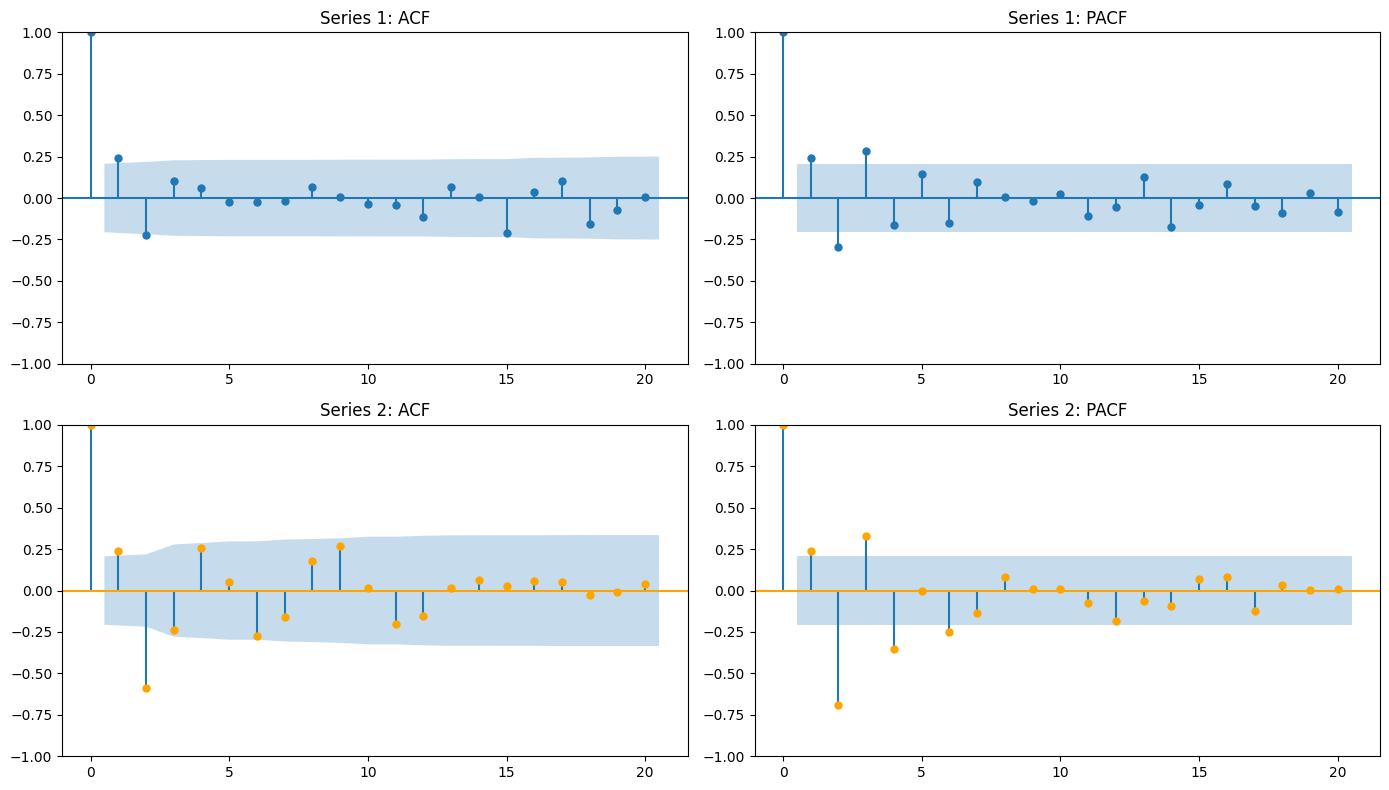

In [19]:
# 2. ACF and PACF diagrams of the estimation set
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(train1['y'], ax=axes[0, 0], title='Series 1: ACF')
plot_pacf(train1['y'], ax=axes[0, 1], title='Series 1: PACF')
plot_acf(train2['y'], ax=axes[1, 0], title='Series 2: ACF', color='orange')
plot_pacf(train2['y'], ax=axes[1, 1], title='Series 2: PACF', color='orange')
plt.tight_layout()
plt.show()

In [25]:
# 4 & 5. Estimating Candidate Models for Series 1
import pandas as pd
candidates_1 = [(1, 0, 0), (0, 0, 1), (1, 0, 1)]
results_1 = []

for order in candidates_1:
    model = ARIMA(train1['y'], order=order).fit()
    results_1.append({
        'Order': f'ARIMA{order}',
        'AIC': round(model.aic, 2),
        'BIC': round(model.bic, 2),
        'Model': model
    })

df_results_1 = pd.DataFrame(results_1)
print(df_results_1[['Order', 'AIC', 'BIC']])

# Display Coefficients for the best fit (ARIMA(1,0,1))
best_model_1 = results_1[2]['Model']
print(best_model_1.summary().tables[1])

            Order     AIC     BIC
0  ARIMA(1, 0, 0)  375.09  382.59
1  ARIMA(0, 0, 1)  357.36  364.86
2  ARIMA(1, 0, 1)  354.73  364.73
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1540      0.268      0.574      0.566      -0.372       0.680
ar.L1         -0.2651      0.176     -1.506      0.132      -0.610       0.080
ma.L1          0.8607      0.081     10.647      0.000       0.702       1.019
sigma2         2.7308      0.390      7.008      0.000       1.967       3.495


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [26]:
# 4 & 5. Estimating Candidate Models for Series 2
import pandas as pd
candidates_2 = [(2, 0, 0), (0, 0, 2), (2, 0, 2)]
results_2 = []

for order in candidates_2:
    model = ARIMA(train2['y'], order=order).fit()
    results_2.append({
        'Order': f'ARIMA{order}',
        'AIC': round(model.aic, 2),
        'BIC': round(model.bic, 2),
        'Model': model
    })

df_results_2 = pd.DataFrame(results_2)
print(df_results_2[['Order', 'AIC', 'BIC']])

# Display Coefficients for the best fit (ARIMA(2,0,2))
best_model_2 = results_2[2]['Model']
print(best_model_2.summary().tables[1])

            Order     AIC     BIC
0  ARIMA(2, 0, 0)  142.12  152.12
1  ARIMA(0, 0, 2)  154.57  164.57
2  ARIMA(2, 0, 2)  125.14  140.14
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0135      0.061      0.222      0.824      -0.106       0.132
ar.L1          0.0599      0.134      0.445      0.656      -0.204       0.323
ar.L2         -0.6456      0.100     -6.445      0.000      -0.842      -0.449
ma.L1          0.7686      0.179      4.283      0.000       0.417       1.120
ma.L2          0.1315      0.159      0.828      0.408      -0.180       0.443
sigma2         0.2008      0.031      6.503      0.000       0.140       0.261


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


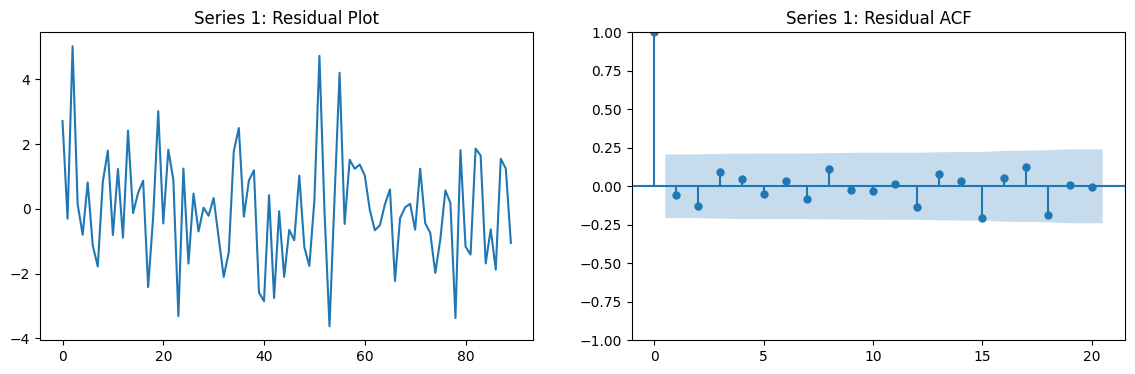

     lb_stat  lb_pvalue
10  5.256366   0.873408


In [27]:
# 6. Residual analysis of Series 1 best model
residuals_1 = best_model_1.resid
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals_1)
axes[0].set_title('Series 1: Residual Plot')
plot_acf(residuals_1, ax=axes[1], title='Series 1: Residual ACF')
plt.show()

# Ljung-Box Test
lb_1 = acorr_ljungbox(residuals_1, lags=[10], return_df=True)
print(lb_1)

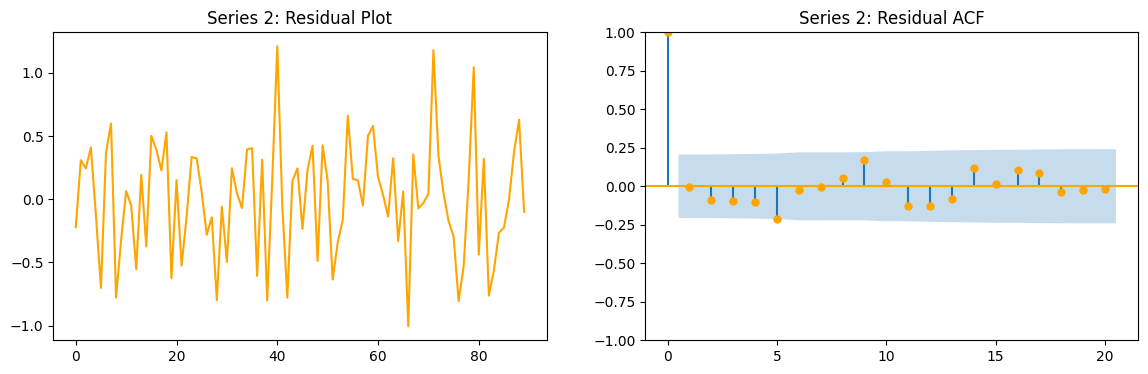

      lb_stat  lb_pvalue
10  10.302164   0.414395


In [28]:
# 6. Residual analysis of Series 2 best model
residuals_2 = best_model_2.resid
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals_2, color='orange')
axes[0].set_title('Series 2: Residual Plot')
plot_acf(residuals_2, ax=axes[1], title='Series 2: Residual ACF', color='orange')
plt.show()

# Ljung-Box Test
lb_2 = acorr_ljungbox(residuals_2, lags=[10], return_df=True)
print(lb_2)

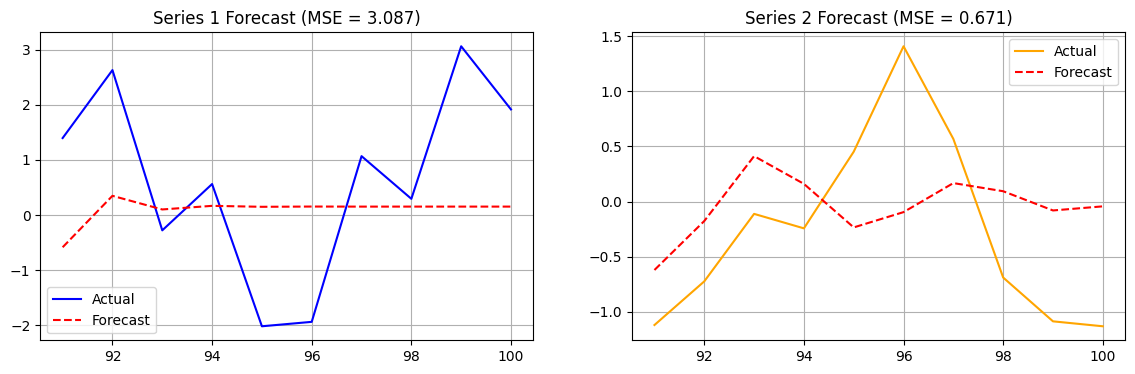

In [29]:
# 7. Forecast and Evaluation (MSE) on the Test Set
import numpy as np
import matplotlib.pyplot as plt

fc_1 = best_model_1.forecast(steps=len(test1))
mse_1 = np.mean((test1['y'].values - fc_1.values) ** 2)

fc_2 = best_model_2.forecast(steps=len(test2))
mse_2 = np.mean((test2['y'].values - fc_2.values) ** 2)

# Plot forecasts
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(test1['t'], test1['y'], label='Actual', color='blue')
axes[0].plot(test1['t'], fc_1, label='Forecast', linestyle='--', color='red')
axes[0].set_title(f'Series 1 Forecast (MSE = {mse_1:.3f})')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(test2['t'], test2['y'], label='Actual', color='orange')
axes[1].plot(test2['t'], fc_2, label='Forecast', linestyle='--', color='red')
axes[1].set_title(f'Series 2 Forecast (MSE = {mse_2:.3f})')
axes[1].legend()
axes[1].grid(True)
plt.show()

## Task

For **each** of the two series (`series1` and `series2`), find an ARIMA(p, 0, q) model that reasonably fits the data. Your analysis should include the following steps:

0. **Estimation/test split.** Partition each series into an estimation (training) set with the first 90% of the observations and a test set with the last 10%. Do not shuffle: the order of a time series matters.
1. **Time series plot** of the training set (the first 90% of the data)
2. **ACF and PACF diagrams** of the estimation set.
3. **Choice of candidate models** (values of p and q) based on the ACF/PACF. Justify the choice.
4. **Table with the estimated coefficients** of each candidate model: coefficient, standard error and p-value.
5. **AIC and BIC** of all candidate models.
6. **Residual analysis of the best model:** residual plot, residual ACF and Ljung-Box tests.
7. **Forecast** of the test set with the best model, and the **mean squared error (MSE)** on the test set.
8. **Choice of the "best" model.** Explain how you selected the model.

## The presentation

- The notebook is your presentation so don't create separate Powerpoint (or similar) files.
- The notebook must not contain prose in markdown (text) other than the instructions here.
- The notebook must not contain printed text other than simple values, e.g. AIC=-493, BIC=-592, MSE=1239 etc. Apart from this, the only
allowed output from code are tables and plots.
- Keep the generated code _simple_. The assignment does not require a lot of programming so if the AI assistant outputs
large chunks of code, make sure to trim these down.

> **Note.** During the presentation you must be able to explain **each diagram and each test**: what it does, why it is used, what conclusions _can_ be drawn from it and what your conclusions are in in the specific case. Expect questions both on the **theory** and on your **concrete results**.

## Submission

The submission **deadline is 22.11.2026 18:00** Sofia local time.

After opening this notebook, save it in your Google drive. Edit it according to the task and keep saving it to your Google drive.
When you are finished with the assignment, click on the "Run All" button in Colab to make sure that it contains all outputs and runs without errors (check for errors!).


1) Download the notebook (File -> Download -> .ipynb (NOT .py))
2) Find the "Share" button in Colab, copy the link and also submit it in Moodle (online text). **Make sure that the link points to your notebook, not to the assignment template in Github**
3) Upload the notebook in Moodle
4) Only one member of the group needs to submit the notebook so make sure that you have written
your names and student ids in the code cell above.
